# Interesting Biological Vignettes

In [15]:
import polars as pl
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append("../../2_individual_assay_results/imaging/2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *

In [16]:
img_scores = pl.read_csv("../../2_individual_assay_results/imaging/3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
img_scores.filter(
    pl.col("gene_allele")=="TPM1_Asn279His"
)

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,Gene_right,U2OS_cc_t_stat_right,U2OS_cc_t_pval_right,U2OS_prot_abun_t_stat_right,U2OS_prot_abun_t_pval_right,…,protein_00001200-a-1 outliers⁺⁺,protein_00001200-b-1 avg,protein_00001200-b-1 outliers⁺⁺,protein_00001200-c-1 avg,protein_00001200-c-1 outliers⁺⁺,protein_00001200-d-1 avg,protein_00001200-d-1 outliers⁺⁺,protein_00001200-e-1 avg,protein_00001200-e-1 outliers⁺⁺,protein_00000061-a-1 avg,protein_00000061-a-1 outliers⁺⁺,protein_00000061-b-1 avg,protein_00000061-b-1 outliers⁺⁺,protein_00000061-c-1 avg,protein_00000061-c-1 outliers⁺⁺,protein_00000061-d-1 avg,protein_00000061-d-1 outliers⁺⁺,protein_00000061-e-1 avg,protein_00000061-e-1 outliers⁺⁺,protein_00000061-f-1 avg,protein_00000061-f-1 outliers⁺⁺,protein_00000061-g-1 avg,protein_00000061-g-1 outliers⁺⁺,protein_00000061-h-1 avg,protein_00000061-h-1 outliers⁺⁺,protein_00000061-i-1 avg,protein_00000061-i-1 outliers⁺⁺,protein_00001002-a-1 avg,protein_00001002-a-1 outliers⁺⁺,protein_00000001-d-2 avg,protein_00000001-d-2 outliers⁺⁺,protein_00001050-a-1 avg,protein_00001050-a-1 outliers⁺⁺,protein_00000703-a-1 avg,protein_00000703-a-1 outliers⁺⁺,protein_00001087-a-1 avg,protein_00001087-a-1 outliers⁺⁺
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,…,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,f64,str,str,str,str,str,str,str
"""TPM1""","""TPM1_Asn279His""",1.451127,0.190037,-11.688567,0.000008,"""2025_03_Batch_15-16""",true,true,true,true,false,true,true,false,true,false,0.998008,0.952603,0.97939,0.985313,0.847208,0.816052,0.980174,0.972844,0.931655,0.997383,0.878364,0.990452,0.985937,0.97355,0.998633,"""TPM1""",1.451127,0.190037,-11.688567,0.000008,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null


In [11]:
allele_meta_df, img_well_qc_sum_df = pl.DataFrame(), pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}
for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio"),
        pl.col("median_plate").mean().alias("median_plate"),
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","median_plate","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","median_plate","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    
    img_well_qc_sum_df = pl.concat(
        [img_well_qc_sum_df, img_well_qc_sum],
        how="diagonal_relaxed"
    )
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

In [18]:
gene_variant = "TPM1_Asn279His"

In [19]:
gene = gene_variant.split('_')[0]

In [20]:
batch_profile_dir = "../../2_individual_assay_results/imaging/2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/batch_profiles"
cell_alleles = pl.concat([
    pl.read_parquet(f"{batch_profile_dir}/2025_03_17_Batch_15/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"),
    pl.read_parquet(f"{batch_profile_dir}/2025_03_17_Batch_16/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet")
], how="diagonal").with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
).select([
    "Metadata_CellID",
    "Metadata_gene_allele",
    "Metadata_Well",
    "Metadata_Plate",
]).filter(
    pl.col("Metadata_gene_allele").str.contains(gene)
)

sc_profile_feat_orig = pl.concat([
    pl.read_parquet(f"{batch_profile_dir}/2025_03_17_Batch_15/profiles_tcdropped_filtered_var_mad_outlier.parquet"),
    pl.read_parquet(f"{batch_profile_dir}/2025_03_17_Batch_16/profiles_tcdropped_filtered_var_mad_outlier.parquet")
], how="diagonal").with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
).filter(
    pl.col("Metadata_gene_allele").str.contains(gene)
)
mad_normalized_gene_profiles = cell_alleles.join(sc_profile_feat_orig, on="Metadata_CellID", how="left")

In [21]:
img_well_qc_sum_ch = img_well_qc_sum_df.filter(pl.col("channel")=="DNA").with_columns(
    pl.col("plate").alias("Metadata_Plate"),
    pl.col("well").alias("Metadata_Well"),
)
print("Original image wells:", mad_normalized_gene_profiles.shape)

mad_normalized_gene_profiles = mad_normalized_gene_profiles.join(
    img_well_qc_sum_ch,
    on=["Metadata_Plate","Metadata_Well"],
    how="left"
).with_columns(
    pl.col("Metadata_Plate").str.extract(r"(B[^A]*)", 1).replace(BIO_BATCH_MAP_DICT).alias("Metadata_Bio_Batch")
)
mad_normalized_gene_profiles = mad_normalized_gene_profiles.filter(~pl.col("is_bg"))
print("QC-ed image wells:", mad_normalized_gene_profiles.shape)

Original image wells: (112622, 2670)
QC-ed image wells: (112467, 2677)


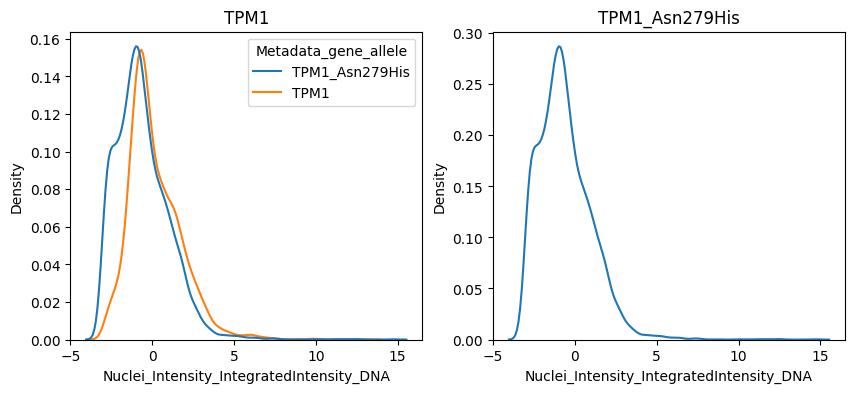

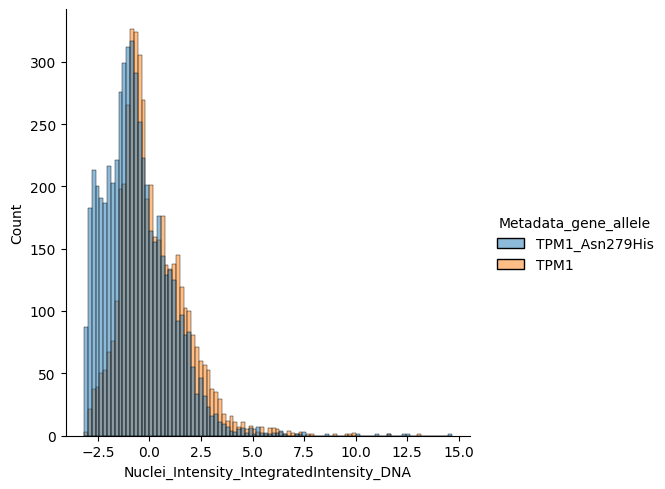

In [35]:
target_feature = "Nuclei_Intensity_IntegratedIntensity_DNA"
batch = mad_normalized_gene_profiles.filter(
    pl.col("Metadata_gene_allele")==gene_variant
)["Metadata_Bio_Batch"].unique()[0]

fig, axes = plt.subplots(1,2,figsize=(10,4))
sns.kdeplot(
    data=mad_normalized_gene_profiles.filter(
        pl.col("Metadata_Bio_Batch")==batch,
        # pl.col("Metadata_gene_allele")==gene,
        (pl.col("Metadata_gene_allele")==gene) | (pl.col("Metadata_gene_allele")==gene_variant)
    ).to_pandas(),
    x=target_feature,
    hue="Metadata_gene_allele",
    ax=axes[0]
)
sns.kdeplot(
    data=mad_normalized_gene_profiles.filter(
        pl.col("Metadata_Bio_Batch")==batch,
        pl.col("Metadata_gene_allele")==gene_variant
    ).to_pandas(),
    x=target_feature,
    # hue="Metadata_gene_allele",
    ax=axes[1]
)
# sns.histplot(
#     data=normalized_ccm2_profiles.filter(
#         pl.col("Metadata_Bio_Batch")==batch,
#         (pl.col("Metadata_gene_allele")==gene_variant) | (pl.col("Metadata_gene_allele")==gene)
#     ).to_pandas(),
#     x="Cytoplasm_Intensity_MeanIntensity_GFP", #"Cells_Intensity_LowerQuartileIntensity_GFP",
#     hue="Metadata_gene_allele",
#     ax=axes[1],
# )
axes[0].set_title(gene)
axes[1].set_title(gene_variant)
sns.displot(
    data=mad_normalized_gene_profiles.filter(
        pl.col("Metadata_Bio_Batch")==batch,
        (pl.col("Metadata_gene_allele")==gene) | (pl.col("Metadata_gene_allele")==gene_variant)
    ).to_pandas(),
    x=target_feature,
    hue="Metadata_gene_allele",
)
plt.show()


# # Filter your data
# filtered_data = normalized_ccm2_profiles.filter(
#     pl.col("Metadata_Bio_Batch")=="B_18-19",
#     pl.col("Metadata_gene_allele")=="CCM2_Val53Ile"
# ).to_pandas()

# conventional_metric = "Cytoplasm_Intensity_IntegratedIntensity_GFP" #"Cells_Intensity_MeanIntensity_GFP", 
# # Create the regplot
# sns.regplot(
#     data=filtered_data,
#     x="Cytoplasm_Intensity_MinIntensityEdge_GFP",
#     y=conventional_metric,
#     ax=axes[2]
# )

# # Calculate Spearman's correlation
# x_data = filtered_data["Cytoplasm_Intensity_MinIntensityEdge_GFP"].dropna()
# y_data = filtered_data[conventional_metric].dropna()

# # Remove rows where either x or y is NaN
# mask = ~(np.isnan(x_data) | np.isnan(y_data))
# x_clean = x_data[mask]
# y_clean = y_data[mask]

# correlation, p_value = spearmanr(x_clean, y_clean)

# # Add correlation text to the plot
# axes[2].text(0.05, 0.95, f'Spearman r = {correlation:.3f}\np = {p_value:.3e}', 
#         transform=axes[2].transAxes, fontsize=10, verticalalignment='top',
#         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
# plt.show()